# R-KalWeNN on House Prices

Implementation and experiments of R-KalWeNN, an extension of the Regression
WiSARD in which every RAM address holds two scalar Kalman filters, one for the
confidence of the address and one for the estimate of the target.

The memory is one dictionary per RAM node, the update runs example by example in
the order of presentation, and each aggregation mean is a function that takes the
list of pairs of one example and returns a number.

## Outline

- **Section 0** data and preprocessing, the same as in the thesis code.
- **Section 1** encoding: thermometer, mapping and addresses.
- **Section 2** the two models, ReW and R-KalWeNN.
- **Section 3** the aggregation means of both families.
- **Section 4** error by aggregation function, with thermometer and tuple fixed.
- **Section 5** thermometer against tuple, and the choice of the operating point.
- **Section 6** the six hyperparameters of the filter.
- **Section 7** other binarisation rules.


---
## 0. Data

Preprocessing of House Prices reproducing the `houseprice.py` of the thesis:
imputation of missing values, skewness correction by Box-Cox, derived attributes,
one-hot encoding and removal of the nearly constant columns. The target is the
sale price in `log(1+x)`.


In [94]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew, boxcox_normmax
from scipy.special import boxcox1p
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

# paleta do artigo
C_REW, C_KAL, C_TRES, C_EIXO, C_TIT = "#db3763", "#16c1d4", "#5c7f44", "#9c7b8e", "#2b2a5e"

BASE_DADOS   = "https://raw.githubusercontent.com/ankita1112/House-Prices-Advanced-Regression/master/"
TEST_SIZE    = 0.33          # houseprice.py
RANDOM_STATE = 0             # houseprice.py
REF_TESE     = 0.278         # MAE da ReW publicado, escala log1p

print("pronto")

pronto


In [95]:
train = pd.read_csv(BASE_DADOS + "train.csv")
test  = pd.read_csv(BASE_DADOS + "test.csv")

train = train[train.GrLivArea < 4500]                  # linha 73 do original
train.reset_index(drop=True, inplace=True)
train["SalePrice"] = np.log1p(train["SalePrice"])      # linha 82: alvo em log1p

train.drop(columns=["Id"], axis=1, inplace=True)
test.drop(columns=["Id"], axis=1, inplace=True)
y = train["SalePrice"].reset_index(drop=True)

all_data = pd.concat((train, test)).reset_index(drop=True)   # linha 106
all_data.drop(["SalePrice"], axis=1, inplace=True)

print(f"train.csv: {train.shape}   test.csv: {test.shape}")
print(f"alvo em log1p: {y.min():.4f} a {y.max():.4f}   média {y.mean():.4f}   desvio {y.std():.4f}")
print(f"  em dólares: ${np.expm1(y.min()):,.0f} a ${np.expm1(y.max()):,.0f}")
print(f"all_data: {all_data.shape}")

train.csv: (1458, 80)   test.csv: (1459, 79)
alvo em log1p: 10.4603 a 13.5345   média 12.0240   desvio 0.3997
  em dólares: $34,900 a $755,000
all_data: (2917, 79)


In [96]:
for c in ["Alley", "PoolQC", "MiscFeature", "Fence", "FireplaceQu", "GarageType",
          "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond",
          "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]:
    all_data[c] = all_data[c].fillna("None")

for c in ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
          "BsmtHalfBath", "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea"]:
    all_data[c] = all_data[c].fillna(0)

all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.mean()))

all_data["MSSubClass"] = all_data["MSSubClass"].astype(str)   # códigos, não quantidades
all_data["MSZoning"] = all_data.groupby("MSSubClass")["MSZoning"].transform(
    lambda x: x.fillna(x.mode()[0]))
all_data["YrSold"] = all_data["YrSold"].astype(str)
all_data["MoSold"] = all_data["MoSold"].astype(str)

all_data["Functional"]  = all_data["Functional"].fillna("Typ")
all_data["Utilities"]   = all_data["Utilities"].fillna("AllPub")
all_data["Exterior1st"] = all_data["Exterior1st"].fillna(all_data["Exterior1st"].mode()[0])
all_data["Exterior2nd"] = all_data["Exterior2nd"].fillna(all_data["Exterior2nd"].mode()[0])
all_data["KitchenQual"] = all_data["KitchenQual"].fillna("TA")
all_data["SaleType"]    = all_data["SaleType"].fillna(all_data["SaleType"].mode()[0])
all_data["Electrical"]  = all_data["Electrical"].fillna("SBrkr")

print(f"colunas com NaN restante: {(all_data.isna().sum() > 0).sum()}")

colunas com NaN restante: 0


In [97]:
def fixing_skewness(df):
    puladas = []
    numeric = df.dtypes[df.dtypes != "object"].index
    skewed = df[numeric].apply(lambda x: skew(x)).sort_values(ascending=False)
    alvo = skewed[abs(skewed) > 0.5].index
    for feat in alvo:
        try:
            df[feat] = boxcox1p(df[feat], boxcox_normmax(df[feat] + 1))
        except Exception:
            puladas.append(feat)
    return len(alvo), puladas


n_alvo, puladas = fixing_skewness(all_data)
print(f"boxcox aplicado em {n_alvo - len(puladas)} de {n_alvo} colunas assimétricas")
if puladas:
    print(f"  sem transformar (BracketError do scipy): {puladas}")

all_data = all_data.drop(["Utilities", "Street", "PoolQC"], axis=1)

all_data["TotalSF"]       = all_data["TotalBsmtSF"] + all_data["1stFlrSF"] + all_data["2ndFlrSF"]
all_data["YrBltAndRemod"] = all_data["YearBuilt"] + all_data["YearRemodAdd"]
all_data["Total_sqr_footage"] = (all_data["BsmtFinSF1"] + all_data["BsmtFinSF2"] +
                                 all_data["1stFlrSF"] + all_data["2ndFlrSF"])
all_data["Total_Bathrooms"]   = (all_data["FullBath"] + 0.5 * all_data["HalfBath"] +
                                 all_data["BsmtFullBath"] + 0.5 * all_data["BsmtHalfBath"])
all_data["Total_porch_sf"]    = (all_data["OpenPorchSF"] + all_data["3SsnPorch"] +
                                 all_data["EnclosedPorch"] + all_data["ScreenPorch"] +
                                 all_data["WoodDeckSF"])

all_data["haspool"]      = (all_data["PoolArea"]    > 0).astype(int)
all_data["has2ndfloor"]  = (all_data["2ndFlrSF"]    > 0).astype(int)
all_data["hasgarage"]    = (all_data["GarageArea"]  > 0).astype(int)
all_data["hasbsmt"]      = (all_data["TotalBsmtSF"] > 0).astype(int)
all_data["hasfireplace"] = (all_data["Fireplaces"]  > 0).astype(int)

final_features = pd.get_dummies(all_data).reset_index(drop=True)
print(f"depois do one-hot: {final_features.shape}")

boxcox aplicado em 25 de 27 colunas assimétricas
  sem transformar (BracketError do scipy): ['LotArea', '1stFlrSF']
depois do one-hot: (2917, 333)


In [98]:
X = final_features.iloc[:len(y), :]

outliers = [30, 88, 462, 631, 1322]
X  = X.drop(X.index[outliers])
y_ = y.drop(y.index[outliers])

def overfit_reducer(df):
    return [c for c in df.columns
            if df[c].value_counts().iloc[0] / len(df) * 100 > 99.94]

descartadas = overfit_reducer(X)
X = X.drop(descartadas, axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_, test_size=TEST_SIZE, random_state=RANDOM_STATE)
X_train, X_test = X_train.values.astype(float), X_test.values.astype(float)
y_train, y_test = y_train.values, y_test.values
N_TREINO, N_ATRIB = len(X_train), X_train.shape[1]

print(f"overfit_reducer descartou {len(descartadas)} colunas -> {X.shape}")
print(f"treino {N_TREINO}   teste {len(X_test)}   atributos {N_ATRIB}")
print(f"a tese reporta:  treino 973   teste 480")
print(f"alvo (log1p): treino {y_train.min():.3f} a {y_train.max():.3f}")

overfit_reducer descartou 1 colunas -> (1453, 332)
treino 973   teste 480   atributos 332
a tese reporta:  treino 973   teste 480
alvo (log1p): treino 10.460 a 13.534


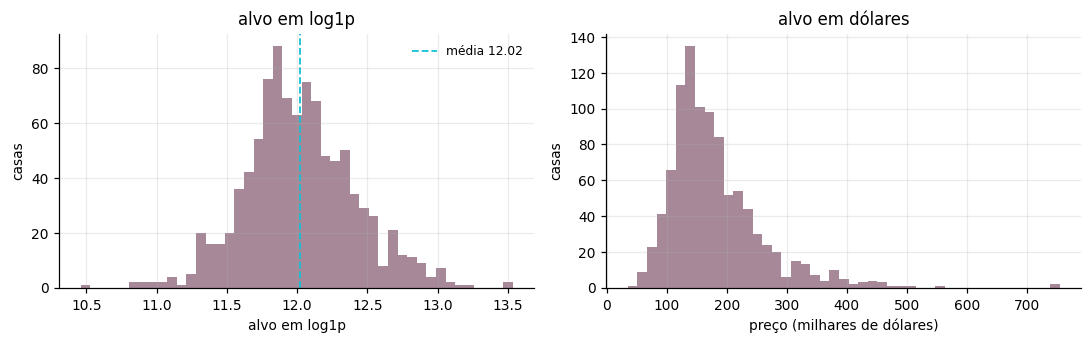

REFERÊNCIAS (escala log1p)

  chutar a média do treino   : MAE 0.3151
  chutar a mediana do treino : MAE 0.3156

  ReW publicada (Neurocomputing 416, Tabela 2): MAE 0.278

  variância do alvo no treino: 0.1537   desvio 0.3920
  0.278 em log1p equivale a 32.0% de erro relativo


In [99]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(y_train, bins=45, color=C_EIXO, alpha=.9)
ax[0].axvline(y_train.mean(), color=C_KAL, ls="--", lw=1.2, label=f"média {y_train.mean():.2f}")
ax[0].set(xlabel="alvo em log1p", ylabel="casas", title="alvo em log1p")
ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(np.expm1(y_train) / 1e3, bins=45, color=C_EIXO, alpha=.9)
ax[1].set(xlabel="preço (milhares de dólares)", ylabel="casas", title="alvo em dólares")
plt.tight_layout(); plt.show()

print("REFERÊNCIAS (escala log1p)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  ReW publicada (Neurocomputing 416, Tabela 2): MAE {REF_TESE:.3f}")
print(f"\n  variância do alvo no treino: {y_train.var():.4f}   desvio {y_train.std():.4f}")
print(f"  {REF_TESE:.3f} em log1p equivale a {np.expm1(REF_TESE):.1%} de erro relativo")

---
## 1. Encoding

Three steps, each one in a function.

The **thermometer** turns every numeric attribute into `t` bits: the value is
compared with `t` thresholds evenly spaced between the minimum and the maximum
the attribute has in the training set, and one bit is set per threshold passed. A
larger value sets more bits.

The **mapping** shuffles the bits of the whole retina and cuts them into pieces
of `a` bits. Each piece is a tuple, and each tuple feeds one RAM node.

The **address** of a RAM node is the integer formed by the `a` bits of its tuple.


In [100]:
def termometro(X, t, mins, maxs):
    """(n, atributos) -> (n, atributos*t) binário.

    É o DynamicThermometer do wisardpkg, que é o que o código da tese executa:
    por atributo, t limiares começando no mínimo do treino e subindo de
    (máximo - mínimo) / t, com comparação ESTRITA. O primeiro limiar é o próprio
    mínimo, então qualquer valor acima dele já acende o primeiro bit, e o valor
    máximo acende todos.
    """
    X = np.atleast_2d(np.asarray(X, dtype=float))
    saida = np.empty((X.shape[0], X.shape[1] * t), dtype=np.uint8)
    for j in range(X.shape[1]):
        passo = (maxs[j] - mins[j]) / t
        limiares = mins[j] + passo * np.arange(t)        # mn, mn+passo, ...
        saida[:, j*t:(j+1)*t] = (X[:, [j]] > limiares).astype(np.uint8)
    return saida


def sorteia_mapping(n_bits, a, seed):
    """Permuta os bits e corta em tuplas de `a`. Sobra é descartada."""
    n_rams = n_bits // a
    rng = np.random.default_rng(seed)
    return rng.permutation(n_bits)[: n_rams * a].reshape(n_rams, a)


def enderecos(Xb, mapping):
    """(n, bits) + (n_rams, a) -> (n, n_rams) com o endereço de cada RAM node."""
    a = mapping.shape[1]
    pesos = 1 << np.arange(a)                      # bit 0 é o menos significativo
    return (Xb[:, mapping] * pesos).sum(axis=2).astype(np.int64)


# conferência: faixa de 0 a 10 com 5 bits tem limiares em 0, 2, 4, 6 e 8
_mins, _maxs = [0.0], [10.0]
esperado = {0.0: "00000", 1.0: "10000", 5.0: "11100", 9.9: "11111", 10.0: "11111"}
for v, bits in esperado.items():
    saiu = "".join(map(str, termometro([[v]], 5, _mins, _maxs)[0]))
    assert saiu == bits, (v, saiu, bits)
    print(f"  valor {v:>4} -> {saiu}")
print("termômetro confere com o DynamicThermometer do wisardpkg")

  valor  0.0 -> 00000
  valor  1.0 -> 10000
  valor  5.0 -> 11100
  valor  9.9 -> 11111
  valor 10.0 -> 11111
termômetro confere com o DynamicThermometer do wisardpkg


---
## 2. The two models

Both keep the memory in the same way: a list with one RAM node per position, and
each RAM node is a dictionary from the address to the content stored there. Only
addresses visited by some training example exist.

**ReW.** Each address holds `[counter, sum of targets]`. Training adds 1 to the
counter and the target to the sum. At prediction time the address returns the
pair, and the aggregation mean decides what to do with it.

**R-KalWeNN.** Each address holds `[c, p_c, y, p_y]`, the confidence and the
estimate with the uncertainty of each one. Training runs the Kalman recursion
twice, once per field, in the order in which the examples appear. At prediction
time the address returns the pair `(c, y)`.


In [101]:
class ReW:
    """Regression WiSARD. Memória: por RAM node, endereço -> [contador, soma]."""

    def __init__(self, mapping):
        self.mapping = mapping
        self.n_rams = mapping.shape[0]

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = enderecos(Xb, self.mapping)
        self.mem = [dict() for _ in range(self.n_rams)]
        for i in range(len(y)):
            for r in range(self.n_rams):
                cel = self.mem[r].get(addr[i, r])
                if cel is None:
                    self.mem[r][addr[i, r]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0
                    cel[1] += y[i]
        return self

    def pares(self, Xb):
        """Para cada exemplo, a lista de [contador, soma] das RAM nodes visitadas."""
        addr = enderecos(Xb, self.mapping)
        saida = []
        for i in range(addr.shape[0]):
            linha = []
            for r in range(self.n_rams):
                cel = self.mem[r].get(addr[i, r])
                if cel is not None:
                    linha.append((cel[0], cel[1]))
            saida.append(linha)
        return saida

    def predict(self, Xb, media):
        return np.array([media(l) for l in self.pares(Xb)])

In [102]:
def passo_kalman(x, p, z, q, r):
    """Uma observação. Devolve o estado e a incerteza depois da correção."""
    p_pred = p + q                 # predição: o estado não muda, a incerteza cresce
    k = p_pred / (p_pred + r)      # ganho
    return x + k * (z - x), (1.0 - k) * p_pred


class RKalWeNN:
    """Memória: por RAM node, endereço -> [c, p_c, y, p_y]."""

    def __init__(self, mapping, p0_c=1.0, q_c=0.1, r_c=6.0,
                 p0_y=1.0, q_y=1e-3, r_y=1.0, x0_c=0.0, x0_y=0.0, seed=0):
        self.mapping = mapping
        self.n_rams = mapping.shape[0]
        self.p0_c, self.q_c, self.r_c = p0_c, q_c, r_c
        self.p0_y, self.q_y, self.r_y = p0_y, q_y, r_y
        self.x0_c, self.x0_y, self.seed = x0_c, x0_y, seed

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = enderecos(Xb, self.mapping)
        self.mem = [dict() for _ in range(self.n_rams)]
        ordem = np.random.default_rng(self.seed).permutation(len(y))
        for i in ordem:
            for r in range(self.n_rams):
                a = addr[i, r]
                cel = self.mem[r].get(a)
                if cel is None:
                    cel = [self.x0_c, self.p0_c, self.x0_y, self.p0_y]
                    self.mem[r][a] = cel
                # campo da confiança: observa sempre 1, o próprio acesso
                cel[0], cel[1] = passo_kalman(cel[0], cel[1], 1.0, self.q_c, self.r_c)
                # campo da estimativa: observa o alvo do exemplo
                cel[2], cel[3] = passo_kalman(cel[2], cel[3], y[i], self.q_y, self.r_y)
        return self

    def pares(self, Xb):
        """Para cada exemplo, a lista de (confiança, estimativa) das RAM nodes visitadas."""
        addr = enderecos(Xb, self.mapping)
        saida = []
        for i in range(addr.shape[0]):
            linha = []
            for r in range(self.n_rams):
                cel = self.mem[r].get(addr[i, r])
                if cel is not None:
                    linha.append((cel[0], cel[2]))
            saida.append(linha)
        return saida

    def predict(self, Xb, media):
        return np.array([media(l) for l in self.pares(Xb)])

    def visitas(self, Xb):
        """Quantas vezes cada endereço ocupado foi visitado no treino."""
        addr = enderecos(Xb, self.mapping)
        cont = []
        for r in range(self.n_rams):
            _, c = np.unique(addr[:, r], return_counts=True)
            cont.append(c)
        return np.concatenate(cont)

---
## 3. The aggregation means

Each mean takes the list of pairs of one example and returns a number.

In the **ReW** family the pair is `(counter, sum)`, and the local value of the
RAM node is the ratio `sum / counter`. Only `Simple` weights the RAM nodes by
their counters, adding the sums and dividing by the total of the counts. The
others treat every visited RAM node alike, dividing by how many of them there
are.

In the **R-KalWeNN** family the pair is `(confidence, estimate)`. The confidence
multiplies the estimate inside the transformation, and the normalisation is
carried out by the sum of the confidences.

The power means use exponent 2.


In [103]:
# ── família ReW: par = (contador, soma) ─────────────────────────────────────
def rew_simple(l):
    sc = sum(c for c, _ in l)
    return sum(s for _, s in l) / sc if sc > 0 else np.nan

def rew_power(l, p=2):
    mus = [s / c for c, s in l if c > 0]
    return (sum(m ** p for m in mus) / len(mus)) ** (1 / p) if mus else np.nan

def rew_harmonic(l):
    mus = [s / c for c, s in l if c > 0 and s / c > 0]
    return len(mus) / sum(1 / m for m in mus) if mus else np.nan

def rew_harmonic_power(l, p=2):
    mus = [s / c for c, s in l if c > 0 and s / c > 0]
    return (len(mus) / sum(1 / m ** p for m in mus)) ** (1 / p) if mus else np.nan

def rew_exponential(l):
    mus = [s / c for c, s in l if c > 0]
    return float(np.log(sum(np.exp(m) for m in mus) / len(mus))) if mus else np.nan

def rew_median(l):
    mus = sorted(s / c for c, s in l if c > 0)
    return float(np.median(mus)) if mus else np.nan


# ── família R-KalWeNN: par = (confiança, estimativa) ────────────────────────
def k_simple(l):
    sc = sum(c for c, _ in l)
    return sum(c * y for c, y in l) / sc if sc > 0 else np.nan

def k_power(l, p=2):
    sc = sum(c for c, _ in l)
    return (sum((c * y) ** p for c, y in l) / sc) ** (1 / p) if sc > 0 else np.nan

def k_harmonic(l):
    par = [(c, y) for c, y in l if y > 0]
    sc = sum(c for c, _ in par)
    return sc / sum(1 / (c*y) for c, y in par) if sc > 0 else np.nan

def k_harmonic_power(l, p=2):
    par = [(c, y) for c, y in l if y > 0]
    sc = sum(c for c, _ in par)
    return (sc / sum((1 /(c * y)) ** p for c, y in par)) ** (1 / p) if sc > 0 else np.nan

def k_exponential(l):
    sc = sum(c for c, _ in l)
    return float(np.log(sum( np.exp(c *y) for c, y in l) / sc)) if sc > 0 else np.nan

def k_median(l):
    mus = sorted(s * c for c, s in l if c > 0)
    return float(np.median(mus)) if mus else np.nan


MEDIAS_REW = {"Simple": rew_simple, "Power": rew_power, "Harmonic": rew_harmonic,
              "Harmonic power": rew_harmonic_power, "Exponential": rew_exponential,
              "Median": rew_median}
MEDIAS_KAL = {"K-Simple": k_simple, "K-Power": k_power, "K-Harmonic": k_harmonic,
              "K-Harmonic power": k_harmonic_power, "K-Exponential": k_exponential,
              "K-Median": k_median}

print("ReW:      ", ", ".join(MEDIAS_REW))
print("R-KalWeNN:", ", ".join(MEDIAS_KAL))

ReW:       Simple, Power, Harmonic, Harmonic power, Exponential, Median
R-KalWeNN: K-Simple, K-Power, K-Harmonic, K-Harmonic power, K-Exponential, K-Median


---
## 4. Error by aggregation function

Thermometer and tuple fixed. Each model runs with the six means of its own
family, and the table reports MAE, RMSE and R².

The seed draws the mapping from bits to RAM nodes, which is the randomness the
two models share, and in R-KalWeNN it also sets the order in which the examples
are presented. The deviation across runs reported in the tables comes from that
source.

The six hyperparameters of the filter are in the second cell of the section, with
both initial states at zero. The first cell prints a diagnosis of the memory at
the operating point: visits per address, with minimum, median and maximum, and
the decomposition of the variance of the target into a part within addresses and
a part between addresses. Those numbers give the order of magnitude of each axis
of the search:

- `r_c` reads in visits, since the confidence of an address reaches one half at
  visit `r_c`;
- `r_y` says how much a single visit is worth against what the address has
  already accumulated, and the ratio between the variance within and between
  addresses is its natural scale;
- each `q` sets in how many visits the address forgets, by `sqrt(r/q)`, and the
  cell prints that window next to the values in use.

With `q` equal to zero the recursion stops depending on the order of presentation
and the address computes a shrunk mean of the observations it received.


In [128]:
THERM, TUPLA = 27, 6
SEEDS_5 = (0, 1, 2, 3, 4)

mins = X_train.min(axis=0).tolist()
maxs = X_train.max(axis=0).tolist()
Xb_tr = termometro(X_train, THERM, mins, maxs)
Xb_te = termometro(X_test,  THERM, mins, maxs)
print(f"retina: {Xb_tr.shape[1]} bits  ({N_ATRIB} atributos x {THERM})")


def diagnostico(Xb, y, mapping):
    """Mede visitas por endereço e decompõe a variância do alvo. Só informação:
    nenhum hiperparâmetro sai daqui, eles são escritos à mão na célula seguinte."""
    addr = enderecos(Xb, mapping)
    n, mu, s2 = [], [], []
    for r in range(mapping.shape[0]):
        _, inv = np.unique(addr[:, r], return_inverse=True)
        cont = np.bincount(inv)
        soma = np.bincount(inv, weights=y)
        n.append(cont); mu.append(soma / cont)
        s2.append(np.bincount(inv, weights=np.asarray(y) ** 2))
    n = np.concatenate(n); mu = np.concatenate(mu); s2 = np.concatenate(s2)
    mult = n > 1
    dentro = float((s2[mult] - n[mult] * mu[mult] ** 2).sum() / (n[mult] - 1).sum())
    entre = float(max(np.var(mu[mult], ddof=1) - dentro * float(np.mean(1 / n[mult])), 1e-6))
    return dict(visitas=n, mediana=float(np.median(n)), dentro=dentro, entre=entre)


mapping0 = sorteia_mapping(Xb_tr.shape[1], TUPLA, seed=0)
diag = diagnostico(Xb_tr, y_train, mapping0)
n0 = diag["visitas"]
print(f"tupla {TUPLA}: {mapping0.shape[0]} RAM nodes, {len(n0):,} endereços ocupados")
print(f"visitas por endereço: mín {n0.min()}, mediana {diag['mediana']:.0f}, máx {n0.max()}")
print(f"variância do alvo {y_train.var(ddof=1):.4f} = dentro {diag['dentro']:.4f}"
      f" + entre {diag['entre']:.4f}")
print(f"razão dentro/entre: {diag['dentro']/diag['entre']:.4f}")

retina: 8964 bits  (332 atributos x 27)
tupla 6: 1494 RAM nodes, 23,171 endereços ocupados
visitas por endereço: mín 1, mediana 6, máx 952
variância do alvo 0.1538 = dentro 0.1237 + entre 0.0877
razão dentro/entre: 1.4100


In [148]:
P0_C = 10          # incerteza inicial da confiança
Q_C  = 0.01           # ruído de processo da confiança
R_C  = 1          # ruído de observação da confiança

P0_Y =  100         # incerteza inicial da estimativa
Q_Y  =  0.0001         # ruído de processo da estimativa
R_Y  =  10         # ruído de observação da estimativa

# ══════════════════════════════════════════════════════════════════════════════

PADRAO = dict(p0_c=P0_C, q_c=Q_C, r_c=R_C, p0_y=P0_Y, q_y=Q_Y, r_y=R_Y,
              x0_c=0.0, x0_y=0.0)

print("HIPERPARÂMETROS EM USO\n")
print(f"  campo da confiança   p0_c = {PADRAO['p0_c']:<12.6g} "
      f"q_c = {PADRAO['q_c']:<12.6g} r_c = {PADRAO['r_c']:.6g}")
print(f"  campo da estimativa  p0_y = {PADRAO['p0_y']:<12.6g} "
      f"q_y = {PADRAO['q_y']:<12.6g} r_y = {PADRAO['r_y']:.6g}")
print(f"  estados iniciais     x0_c = {PADRAO['x0_c']:<12.6g} "
      f"x0_y = {PADRAO['x0_y']:.6g}")

HIPERPARÂMETROS EM USO

  campo da confiança   p0_c = 10           q_c = 0.01         r_c = 1
  campo da estimativa  p0_y = 100          q_y = 0.0001       r_y = 10
  estados iniciais     x0_c = 0            x0_y = 0


In [149]:
def metricas(y_ref, pred):
    pred = np.asarray(pred, dtype=float)
    nao_fin = int((~np.isfinite(pred)).sum())
    if nao_fin:
        bons = pred[np.isfinite(pred)]
        pred = np.where(np.isfinite(pred), pred, bons.mean() if len(bons) else 0.0)
    ss = float(np.sum((y_ref - y_ref.mean()) ** 2))
    return (mean_absolute_error(y_ref, pred),
            float(np.sqrt(mean_squared_error(y_ref, pred))),
            1.0 - float(np.sum((y_ref - pred) ** 2)) / ss,
            nao_fin, float(np.std(pred)))


acum, t0 = {}, time.perf_counter()
for sd in SEEDS_5:
    mp = sorteia_mapping(Xb_tr.shape[1], TUPLA, seed=sd)

    rw = ReW(mp).fit(Xb_tr, y_train)
    pares_rw = rw.pares(Xb_te)
    for nome, f in MEDIAS_REW.items():
        acum.setdefault(("ReW", nome), []).append(
            metricas(y_test, [f(l) for l in pares_rw]))

    kw = RKalWeNN(mp, seed=sd, **PADRAO).fit(Xb_tr, y_train)
    pares_kw = kw.pares(Xb_te)
    for nome, f in MEDIAS_KAL.items():
        acum.setdefault(("R-KalWeNN", nome), []).append(
            metricas(y_test, [f(l) for l in pares_kw]))
    print(f"  execução {sd}  ...  {time.perf_counter()-t0:.0f}s")

linhas = []
for (modelo, nome), vals in acum.items():
    v = np.array([[a, b, c, e] for a, b, c, _, e in vals])
    linhas.append(dict(modelo=modelo, media=nome,
                       MAE=v[:, 0].mean(), MAE_dp=v[:, 0].std(ddof=1),
                       RMSE=v[:, 1].mean(), R2=v[:, 2].mean(),
                       desvio_pred=v[:, 3].mean()))
tab5 = pd.DataFrame(linhas).sort_values(["modelo", "MAE"])
print(f"\n{len(SEEDS_5)} execuções, thermometer {THERM}, tupla {TUPLA}\n")
print(tab5.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nReW publicada na tese : MAE {REF_TESE:.3f}")
print(f"chutar a média        : MAE {mae_media:.4f}")
print(f"desvio do alvo no teste: {y_test.std():.4f}   "
      "(comparar com a coluna desvio_pred: predição achatada erra mais)")

  execução 0  ...  22s
  execução 1  ...  40s
  execução 2  ...  59s
  execução 3  ...  81s
  execução 4  ...  114s

5 execuções, thermometer 27, tupla 6

   modelo            media    MAE  MAE_dp   RMSE     R2  desvio_pred
R-KalWeNN K-Harmonic power 0.2459  0.0003 0.3315 0.3342       0.1049
R-KalWeNN       K-Harmonic 0.2464  0.0004 0.3323 0.3311       0.1069
R-KalWeNN          K-Power 0.2469  0.0002 0.3314 0.3345       0.0939
R-KalWeNN         K-Simple 0.2471  0.0002 0.3313 0.3352       0.0921
R-KalWeNN    K-Exponential 0.2484  0.0002 0.3322 0.3315       0.0903
R-KalWeNN         K-Median 0.2744  0.0014 0.3611 0.2101       0.0557
      ReW      Exponential 0.2480  0.0001 0.3296 0.3418       0.0884
      ReW   Harmonic power 0.2481  0.0001 0.3314 0.3347       0.0880
      ReW         Harmonic 0.2481  0.0001 0.3313 0.3350       0.0880
      ReW            Power 0.2481  0.0001 0.3311 0.3359       0.0878
      ReW           Median 0.2736  0.0007 0.3592 0.2181       0.0560
      ReW        

---
## 5. Thermometer against tuple

A sweep on both axes, measuring three things per configuration: the error of the
two models, how many times each address is visited, and how many addresses were
seen only once.

The error alone pushes the tuple upwards, because a larger address separates the
examples more. The access structure pulls it down, because with a large tuple
each address is seen only once, the prediction becomes a lookup and the memory
grows.

The operating point is the one with the lowest error among the configurations
that preserve revisiting, under two simultaneous criteria: a median of at least
`LIM_MEDIANA` visits per address, and at most `LIM_UMA` per cent of the addresses
seen only once. The printed table shows what each tuple delivers.

R-KalWeNN runs with the hyperparameters of Section 4, the same ones throughout
the sweep, so that what varies here is only the encoding. The thermometer sweeps
in steps of 3 bits.


In [132]:
SW_THERM = list(range(6, 31, 3))
SW_TUPLA = [2, 4, 6, 9, 12, 27, 36, 54]
SW_SEEDS = (0, 1, 2, 3, 4)
MEDIA_REW_7, MEDIA_KAL_7 = MEDIA_REW_6, MEDIA_KAL_6

LIM_MEDIANA = 6.0     # mediana de visitas por endereço, no mínimo
LIM_UMA     = 25.0    # porcentagem de endereços vistos uma única vez, no máximo

linhas7, t0 = [], time.perf_counter()
for t in SW_THERM:
    Xb_t, Xb_s = termometro(X_train, t, mins, maxs), termometro(X_test, t, mins, maxs)
    for a in SW_TUPLA:
        if Xb_t.shape[1] // a < 2:
            continue
        mae_r, mae_k, vis, uma = [], [], None, None
        for sd in SW_SEEDS:
            mp = sorteia_mapping(Xb_t.shape[1], a, seed=sd)
            dg = diagnostico(Xb_t, y_train, mp)
            hp = dict(PADRAO)
            rw = ReW(mp).fit(Xb_t, y_train)
            mae_r.append(metricas(y_test, [MEDIAS_REW[MEDIA_REW_7](l)
                                           for l in rw.pares(Xb_s)])[0])
            kw = RKalWeNN(mp, seed=sd, **hp).fit(Xb_t, y_train)
            mae_k.append(metricas(y_test, [MEDIAS_KAL[MEDIA_KAL_7](l)
                                           for l in kw.pares(Xb_s)])[0])
            if vis is None:
                n = dg["visitas"]
                vis, uma = dg["mediana"], 100.0 * float((n == 1).mean())
                rams, ocup = mp.shape[0], len(n)
        linhas7.append(dict(therm=t, tupla=a, n_rams=rams, enderecos=ocup,
                            visitas_mediana=vis, pct_uma=uma,
                            MAE_rew=float(np.mean(mae_r)),
                            MAE_kal=float(np.mean(mae_k)),
                            MAE_kal_dp=float(np.std(mae_k))))
    print(f"  thermometer {t:>2} ... {time.perf_counter()-t0:5.0f}s")

sup = pd.DataFrame(linhas7)
sup.to_csv("varredura_08.csv", index=False)

por_tupla = sup.groupby("tupla").agg(
    visitas=("visitas_mediana", "median"), uma_pct=("pct_uma", "median"),
    rams=("n_rams", "median"), MAE_rew=("MAE_rew", "min"), MAE_kal=("MAE_kal", "min"))
print("\n" + por_tupla.to_string(float_format=lambda v: f"{v:.3f}"))

elegiveis = sup[(sup.visitas_mediana >= LIM_MEDIANA) & (sup.pct_uma <= LIM_UMA)]
print(f"\nlimiar: mediana >= {LIM_MEDIANA:g} visitas e no máximo {LIM_UMA:g}% vistos uma vez")
print(f"configurações elegíveis: {len(elegiveis)} de {len(sup)}")
if len(elegiveis):
    esc = elegiveis.loc[elegiveis.MAE_kal.idxmin()]
    T_OK, A_OK = int(esc.therm), int(esc.tupla)
    print(f"escolha: thermometer {T_OK}, tupla {A_OK}, "
          f"MAE {esc.MAE_kal:.4f}, {int(esc.n_rams)} RAM nodes, "
          f"mediana de {esc.visitas_mediana:.0f} visitas, {esc.pct_uma:.0f}% vistos uma vez")
else:
    T_OK, A_OK = THERM, TUPLA
    print("nenhuma configuração passa no limiar; mantendo o ponto da Seção 5")

  thermometer  6 ...    83s
  thermometer  9 ...   236s
  thermometer 12 ...   455s
  thermometer 15 ...   697s
  thermometer 18 ...   987s
  thermometer 21 ...  1274s
  thermometer 24 ...  1652s
  thermometer 27 ...  2045s
  thermometer 30 ...  2594s

       visitas  uma_pct     rams  MAE_rew  MAE_kal
tupla                                             
2       57.000    8.148 2988.000    0.289    0.288
4       14.000   16.289 1494.000    0.266    0.265
6        6.000   23.283  996.000    0.247    0.246
9        3.000   31.601  664.000    0.224    0.225
12       2.000   38.927  498.000    0.207    0.217
27       1.000   63.119  221.000    0.161    0.403
36       1.000   72.578  166.000    0.148    0.596
54       1.000   84.792  110.000    0.137    0.944

limiar: mediana >= 6 visitas e no máximo 25% vistos uma vez
configurações elegíveis: 27 de 72
escolha: thermometer 9, tupla 6, MAE 0.2455, 498 RAM nodes, mediana de 6 visitas, 23% vistos uma vez


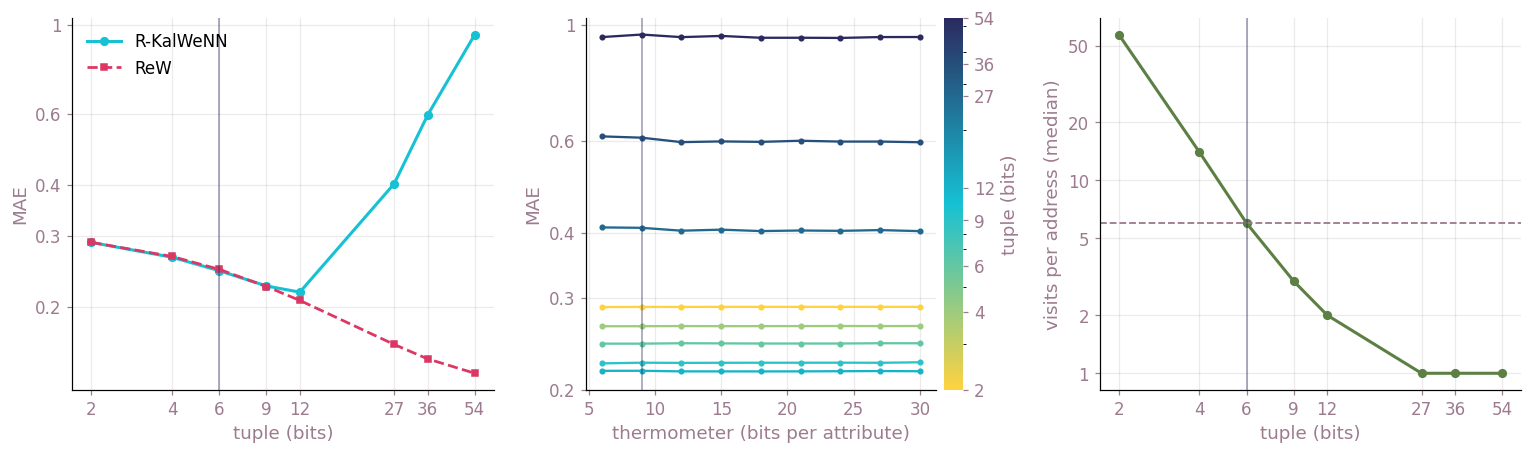

In [152]:
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.cm import ScalarMappable

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), facecolor="white")
TAM_ROT, TAM_MARCA, TAM_LEG = 12, 11, 11

# ── erro contra tupla, os dois modelos ──────────────────────────────────────
ax[0].plot(por_tupla.index, por_tupla.MAE_kal, "o-", lw=2, ms=5, color=C_KAL,
           label="R-KalWeNN")
ax[0].plot(por_tupla.index, por_tupla.MAE_rew, "s--", lw=1.8, ms=4, color=C_REW,
           label="ReW")
ax[0].set(xlabel="tuple (bits)", ylabel="MAE", xscale="log", yscale="log")
ax[0].set_xticks(SW_TUPLA); ax[0].set_xticklabels(SW_TUPLA)
# rótulos do eixo y em número, não em potência de dez
marcas0 = [0.2, 0.3, 0.4, 0.6, 1.0]
ax[0].set_yticks(marcas0)
ax[0].set_yticklabels([f"{v:g}" for v in marcas0])
ax[0].minorticks_off()
ax[0].legend(frameon=False, fontsize=TAM_LEG, loc="upper left")

# ── erro contra thermometer, uma linha por tupla, cor no lugar de legenda ───
CMAP = LinearSegmentedColormap.from_list("tupla", ["#ffd23f", "#16c1d4", "#2b2a5e"])
norm = LogNorm(vmin=min(SW_TUPLA), vmax=max(SW_TUPLA))
for a_, g in sup.groupby("tupla"):
    g = g.sort_values("therm")
    ax[1].plot(g.therm, g.MAE_kal, "-o", ms=3, lw=1.5, color=CMAP(norm(a_)))
ax[1].set(xlabel="thermometer (bits per attribute)", ylabel="MAE", yscale="log")
marcas1 = [0.2, 0.3, 0.4, 0.6, 1.0]
ax[1].set_yticks(marcas1)
ax[1].set_yticklabels([f"{v:g}" for v in marcas1])
ax[1].minorticks_off()
cb = fig.colorbar(ScalarMappable(norm=norm, cmap=CMAP), ax=ax[1], pad=0.02)
cb.set_label("tuple (bits)", color=C_EIXO, fontsize=TAM_ROT)
cb.set_ticks(SW_TUPLA); cb.set_ticklabels([str(t) for t in SW_TUPLA])
cb.ax.tick_params(labelsize=TAM_MARCA, colors=C_EIXO); cb.outline.set_visible(False)

# ── visitas por endereço contra tupla ───────────────────────────────────────
ax[2].plot(por_tupla.index, por_tupla.visitas, "o-", lw=2, ms=5, color=C_TRES)
ax[2].axhline(LIM_MEDIANA, color=C_EIXO, ls="--", lw=1.2)
ax[2].set(xlabel="tuple (bits)", ylabel="visits per address (median)",
          xscale="log", yscale="log")
ax[2].set_xticks(SW_TUPLA); ax[2].set_xticklabels(SW_TUPLA)
# rótulos do eixo y em número, não em potência de dez
marcas_y = [1, 2, 5, 10, 20, 50]
ax[2].set_yticks(marcas_y); ax[2].set_yticklabels([str(v) for v in marcas_y])
ax[2].minorticks_off()

for e in (ax[0], ax[2]):
    e.axvline(A_OK, color=C_TIT, lw=1.2, alpha=.4)
ax[1].axvline(T_OK, color=C_TIT, lw=1.2, alpha=.4)
for e in ax:
    e.tick_params(colors=C_EIXO, labelsize=TAM_MARCA)
    e.xaxis.label.set_color(C_EIXO); e.yaxis.label.set_color(C_EIXO)
    e.xaxis.label.set_fontsize(TAM_ROT); e.yaxis.label.set_fontsize(TAM_ROT)
plt.tight_layout(); plt.show()

---
## 6. The six hyperparameters

Three cells, all at the operating point chosen in Section 5.

The first sweeps one hyperparameter at a time over its grid, with the other five
held at the values of Section 4. The second records, for each configuration, the
six hyperparameters together with the encoding and the size of the memory. The
third sweeps the cartesian product of the six grids, which also covers the
interaction between the axes, writes the result to `varredura_completa_08.csv`
and draws one panel per hyperparameter, with the median error and the lowest
error at each level.


ponto de operação: thermometer 9, tupla 6
  p0_c  = 100
  q_c   = 0.001
  r_c   = 10
  p0_y  = 1000
  q_y   = 0.0001
  r_y   = 10
  x0_c  = 0
  x0_y  = 0
  p0_c  ...    39s
  q_c   ...    84s
  r_c   ...   115s
  p0_y  ...   143s
  q_y   ...   174s
  r_y   ...   207s


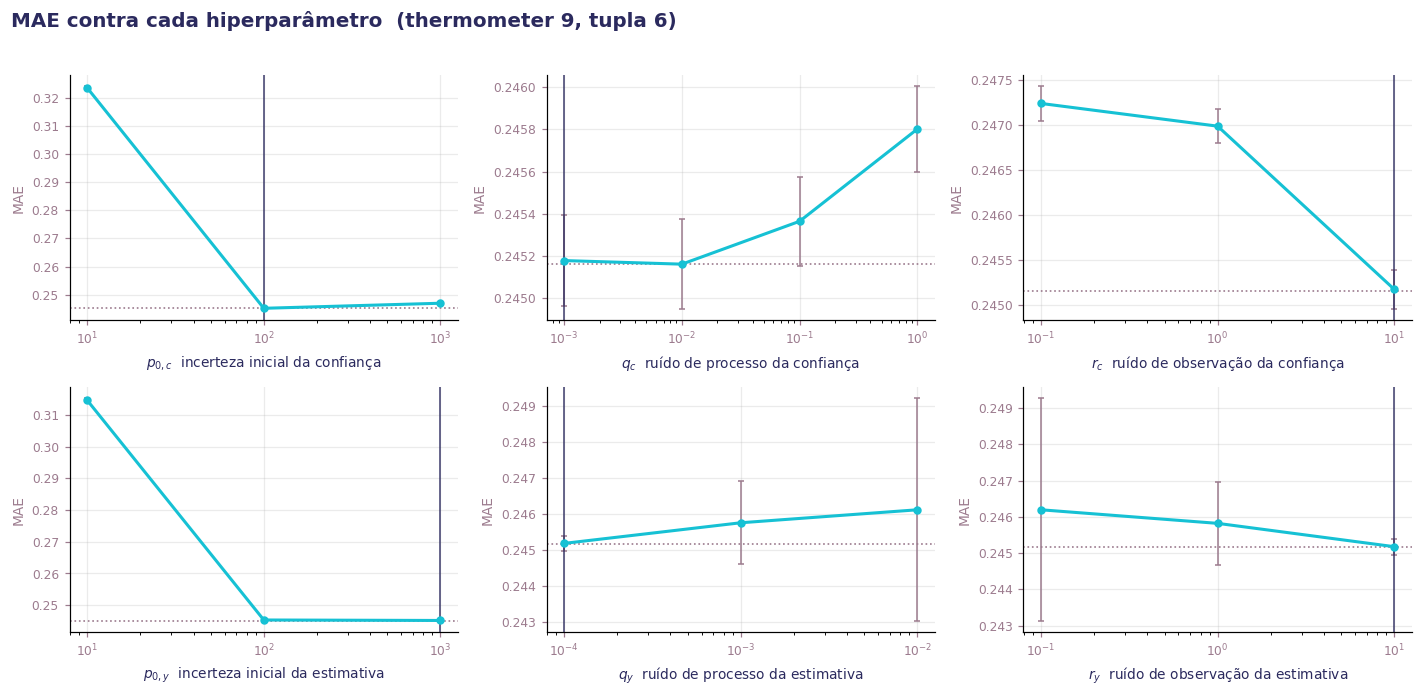


melhor nível de cada hiperparâmetro

  p0_c  padrão         100   melhor         100   MAE 0.2452   interior
  q_c   padrão       0.001   melhor        0.01   MAE 0.2452   interior
  r_c   padrão          10   melhor          10   MAE 0.2452   MAIOR nível
  p0_y  padrão        1000   melhor        1000   MAE 0.2452   MAIOR nível
  q_y   padrão      0.0001   melhor      0.0001   MAE 0.2452   MENOR nível
  r_y   padrão          10   melhor          10   MAE 0.2452   MAIOR nível


In [144]:
SEEDS_8 = (0, 1, 2, 3, 4)

GRADES = {
    "p0_c": [10.0, 100.0, 1000.0],
    "q_c":  [0.001, 0.01, 0.1, 1.0],
    "r_c":  [0.1, 1.0, 10],
    "p0_y": [10.0, 100.0, 1000.0],
    "q_y":  [0.0001, 0.001, 0.01],
    "r_y":  [0.1, 1.0, 10.0],
}
ROTULO = {"p0_c": "$p_{0,c}$  incerteza inicial da confiança",
          "q_c": "$q_c$  ruído de processo da confiança",
          "r_c": "$r_c$  ruído de observação da confiança",
          "p0_y": "$p_{0,y}$  incerteza inicial da estimativa",
          "q_y": "$q_y$  ruído de processo da estimativa",
          "r_y": "$r_y$  ruído de observação da estimativa"}

Xb_t8 = termometro(X_train, T_OK, mins, maxs)
Xb_s8 = termometro(X_test,  T_OK, mins, maxs)
map_8 = sorteia_mapping(Xb_t8.shape[1], A_OK, seed=0)
PADRAO_8 = dict(PADRAO)   # os valores escritos à mão na Seção 5
print(f"ponto de operação: thermometer {T_OK}, tupla {A_OK}")
for k, v in PADRAO_8.items():
    dentro = k not in GRADES or min(GRADES[k]) <= v <= max(GRADES[k])
    marca = "" if dentro else "   >>> FORA DA GRADE <<<"
    print(f"  {k:5s} = {v:.6g}{marca}")

linhas8, t0 = [], time.perf_counter()
for par, grade in GRADES.items():
    for v in grade:
        hp = dict(PADRAO_8); hp[par] = v
        maes = []
        for sd in SEEDS_8:
            kw = RKalWeNN(map_8, seed=sd, **hp).fit(Xb_t8, y_train)
            maes.append(metricas(y_test, [MEDIAS_KAL[MEDIA_KAL_7](l)
                                          for l in kw.pares(Xb_s8)])[0])
        linhas8.append(dict(parametro=par, valor=v,
                            MAE=float(np.mean(maes)), MAE_dp=float(np.std(maes))))
    print(f"  {par:5s} ... {time.perf_counter()-t0:5.0f}s")
sens = pd.DataFrame(linhas8)
sens.to_csv("sensibilidade_08.csv", index=False)

piso = float(sens.MAE.min())
fig, ax = plt.subplots(2, 3, figsize=(13, 6.4), facecolor="white")
for a_, par in zip(ax.ravel(), GRADES):
    g = sens[sens.parametro == par].sort_values("valor")
    a_.errorbar(g.valor, g.MAE, yerr=g.MAE_dp, fmt="o-", lw=2, ms=4.5,
                color=C_KAL, ecolor=C_EIXO, elinewidth=1, capsize=2)
    a_.axvline(PADRAO_8[par], color=C_TIT, lw=1.3, alpha=.7)
    a_.axhline(piso, color=C_EIXO, ls=":", lw=1.1)
    a_.set(xscale="log", xlabel=ROTULO[par], ylabel="MAE")
    a_.tick_params(colors=C_EIXO, labelsize=8)
    a_.xaxis.label.set_color(C_TIT); a_.yaxis.label.set_color(C_EIXO)
fig.suptitle(f"MAE contra cada hiperparâmetro  (thermometer {T_OK}, tupla {A_OK})",
             fontsize=13, fontweight="bold", color=C_TIT, x=0.01, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

print("\nmelhor nível de cada hiperparâmetro\n")
for par, grade in GRADES.items():
    g = sens[sens.parametro == par]
    b = g.loc[g.MAE.idxmin()]
    borda = ("MENOR nível" if b.valor == min(grade)
             else "MAIOR nível" if b.valor == max(grade) else "interior")
    print(f"  {par:5s} padrão {PADRAO_8[par]:>11.5g}   melhor {b.valor:>11.5g}"
          f"   MAE {b.MAE:.4f}   {borda}")

In [111]:
# Mesma varredura da célula acima, registrando a configuração inteira de cada
# ponto: os seis hiperparâmetros, a codificação e o tamanho da memória.
# Uma linha por ponto da grade, com o valor que foi variado e os cinco que
# ficaram parados.

MEDIA_TAB = MEDIA_KAL_7 if "MEDIA_KAL_7" in globals() else "K-Harmonic power"
map_tab = sorteia_mapping(Xb_t8.shape[1], A_OK, seed=0)

linhas, t0 = [], time.perf_counter()
for par, grade in GRADES.items():
    for v in grade:
        hp = dict(PADRAO_8); hp[par] = v
        vals = []
        for sd in SEEDS_8:
            kw = RKalWeNN(map_tab, seed=sd, **hp).fit(Xb_t8, y_train)
            vals.append(metricas(y_test, [MEDIAS_KAL[MEDIA_TAB](l)
                                          for l in kw.pares(Xb_s8)]))
        a = np.array([[x, y_, z] for x, y_, z, _, _ in vals])
        linhas.append(dict(variado=par, therm=T_OK, address=A_OK,
                           n_rams=map_tab.shape[0], media=MEDIA_TAB,
                           q_c=hp["q_c"], r_c=hp["r_c"], p0_c=hp["p0_c"],
                           q_y=hp["q_y"], r_y=hp["r_y"], p0_y=hp["p0_y"],
                           MAE=a[:, 0].mean(), MAE_dp=a[:, 0].std(ddof=1),
                           R2=a[:, 2].mean()))
    print(f"  {par:5s} ... {time.perf_counter()-t0:5.0f}s")

COLS = ["therm", "address", "n_rams", "media", "q_c", "r_c", "p0_c",
        "q_y", "r_y", "p0_y", "MAE", "MAE_dp", "R2"]
tab_hp = pd.DataFrame(linhas)
tab_hp.to_csv("hiperparametros_08.csv", index=False)

fmt = lambda v: f"{v:.6g}"
print(f"\nCONFIGURAÇÃO PADRÃO (a linha de onde todas partem)\n")
base = dict(therm=T_OK, address=A_OK, n_rams=map_tab.shape[0], media=MEDIA_TAB,
            **{k: PADRAO_8[k] for k in ["q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y"]})
linha_base = tab_hp[(tab_hp[["q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y"]]
                     == pd.Series({k: PADRAO_8[k] for k in
                                   ["q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y"]})).all(axis=1)]
if len(linha_base):
    print(linha_base[COLS].head(1).to_string(index=False, float_format=fmt))
else:
    print(pd.DataFrame([base])[COLS[:-3]].to_string(index=False, float_format=fmt),
          "   (não está na grade)")

print(f"\n\nTODOS OS PONTOS, do melhor para o pior\n")
print(tab_hp.sort_values("MAE")[["variado"] + COLS]
      .to_string(index=False, float_format=fmt))

print(f"\n\nMELHOR DE CADA EIXO\n")
melhores = tab_hp.loc[tab_hp.groupby("variado").MAE.idxmin()]
print(melhores[["variado"] + COLS].sort_values("MAE")
      .to_string(index=False, float_format=fmt))

  p0_c  ...    84s
  q_c   ...   170s
  r_c   ...   246s
  p0_y  ...   316s
  q_y   ...   362s
  r_y   ...   437s

CONFIGURAÇÃO PADRÃO (a linha de onde todas partem)

 therm  address  n_rams            media   q_c  r_c  p0_c    q_y  r_y  p0_y      MAE      MAE_dp       R2
    21        6    1162 K-Harmonic power 0.001   10   100 0.0001   10  1000 0.245185 0.000305761 0.340267


TODOS OS PONTOS, do melhor para o pior

variado  therm  address  n_rams            media   q_c    r_c  p0_c    q_y  r_y  p0_y      MAE      MAE_dp        R2
   p0_c     21        6    1162 K-Harmonic power 0.001     10   100 0.0001   10  1000 0.245185 0.000305761  0.340267
    r_y     21        6    1162 K-Harmonic power 0.001     10   100 0.0001   10  1000 0.245185 0.000305761  0.340267
    q_y     21        6    1162 K-Harmonic power 0.001     10   100 0.0001   10  1000 0.245185 0.000305761  0.340267
   p0_y     21        6    1162 K-Harmonic power 0.001     10   100 0.0001   10  1000 0.245185 0.000305761  0.3

In [146]:
# Varredura COMPLETA: produto cartesiano das grades da célula acima, sem
# manter nada parado. Usa exatamente os valores de GRADES, sem acrescentar nível.
# É a varredura que enxerga interação entre os eixos, e é a cara: o número de
# combinações é o produto dos tamanhos das seis grades.

from itertools import product

# ══════════════════════════════════════════════════════════════════════════════
#  CONFIRA A GRADE ANTES DE RODAR
#
#  Com CONFIRMAR = False a célula só imprime o plano e para. Depois de conferir,
#  troque para True e rode de novo. A grade vem do GRADES da célula acima, então
#  o que for impresso aqui é exatamente o que será varrido.
# ══════════════════════════════════════════════════════════════════════════════

CONFIRMAR  = True
SEEDS_FULL = (0, 1, 2, 3, 4)
MEDIA_FULL = MEDIA_KAL_7 if "MEDIA_KAL_7" in globals() else "K-Harmonic power"
ARQ_FULL   = "varredura_completa_08.csv"

EIXOS = ["p0_c", "q_c", "r_c", "p0_y", "q_y", "r_y"]

# A GRADES vem da célula acima. Se ela foi editada e não foi executada de novo,
# o kernel ainda guarda a grade velha, então aqui a da memória é conferida
# contra a que está escrita no arquivo do notebook.
import ast, json
_src = "".join(next(cl["source"] for cl in json.load(open("LaFusion26_r-kalwenn-house-prices.ipynb"))["cells"]
                    if cl["id"] == "e8"))
_i = _src.index("GRADES = {")
GRADE_ARQ = ast.literal_eval(_src[_i + len("GRADES = "):_src.index("}", _i) + 1])
if {k: [float(v) for v in vs] for k, vs in GRADES.items()} != \
   {k: [float(v) for v in vs] for k, vs in GRADE_ARQ.items()}:
    print("A GRADES do kernel NÃO é a que está escrita na célula acima.")
    for e in EIXOS:
        print(f"  {e:5s} memória: {GRADES[e]}")
        print(f"        arquivo: {GRADE_ARQ[e]}")
    print("\nRode a célula acima e depois esta. Nada foi executado.")
    raise SystemExit
combos = list(product(*[GRADES[e] for e in EIXOS]))
map_full = sorteia_mapping(Xb_t8.shape[1], A_OK, seed=0)

print("=" * 66)
print("PLANO DA VARREDURA COMPLETA")
print("=" * 66)
print(f"  thermometer {T_OK}, tupla {A_OK}, {map_full.shape[0]} RAM nodes")
print(f"  agregação   {MEDIA_FULL}")
print(f"  estados     x0_c = {PADRAO_8['x0_c']:g}, x0_y = {PADRAO_8['x0_y']:g}")
print(f"  arquivo     {ARQ_FULL}\n")
print("  GRADE, um eixo por linha\n")
for e in EIXOS:
    vals = "  ".join(f"{v:g}" for v in GRADES[e])
    print(f"    {e:5s} {len(GRADES[e])} níveis :  {vals}")
print(f"\n  {' x '.join(str(len(GRADES[e])) for e in EIXOS)} = {len(combos):,} combinações")
print(f"  {len(combos):,} combinações x {len(SEEDS_FULL)} sementes "
      f"= {len(combos)*len(SEEDS_FULL):,} treinos")
print("=" * 66)

if not CONFIRMAR:
    print("\nCONFIRMAR está em False: nada foi executado.")
    print("Confira a grade acima, troque para True e rode de novo.")
    raise SystemExit

linhas, t0 = [], time.perf_counter()
for n, valores in enumerate(combos, 1):
    hp = dict(zip(EIXOS, valores), x0_c=PADRAO_8["x0_c"], x0_y=PADRAO_8["x0_y"])
    vals = []
    for sd in SEEDS_FULL:
        kw = RKalWeNN(map_full, seed=sd, **hp).fit(Xb_t8, y_train)
        vals.append(metricas(y_test, [MEDIAS_KAL[MEDIA_FULL](l)
                                      for l in kw.pares(Xb_s8)]))
    a = np.array([[x, y_, z] for x, y_, z, _, _ in vals])
    linhas.append(dict(therm=T_OK, address=A_OK, n_rams=map_full.shape[0],
                       media=MEDIA_FULL, **dict(zip(EIXOS, valores)),
                       MAE=a[:, 0].mean(), MAE_dp=a[:, 0].std(ddof=1),
                       R2=a[:, 2].mean()))
    if n % 25 == 0 or n == len(combos):
        el = time.perf_counter() - t0
        print(f"  {n:>5}/{len(combos)}   {el/60:5.1f} min, "
              f"faltam ~{el/n*(len(combos)-n)/60:5.1f} min")

full = pd.DataFrame(linhas)
full.to_csv(ARQ_FULL, index=False)

COLS = ["therm", "address", "n_rams", "media", "q_c", "r_c", "p0_c",
        "q_y", "r_y", "p0_y", "MAE", "MAE_dp", "R2"]
fmt = lambda v: f"{v:.6g}"
print(f"\n\nAS 20 MELHORES\n")
print(full.nsmallest(20, "MAE")[COLS].to_string(index=False, float_format=fmt))
print(f"\nAS 5 PIORES\n")
print(full.nlargest(5, "MAE")[COLS].to_string(index=False, float_format=fmt))
print(f"\nfaixa de MAE: {full.MAE.min():.4f} a {full.MAE.max():.4f}")

print(f"\n\nO VENCEDOR CAIU NA BORDA DE ALGUM EIXO?\n")
melhor = full.loc[full.MAE.idxmin()]
for e in EIXOS:
    niveis = sorted(GRADES[e])
    onde = ("MENOR nível" if melhor[e] == niveis[0]
            else "MAIOR nível" if melhor[e] == niveis[-1] else "interior")
    print(f"  {e:5s} = {melhor[e]:<10g} {onde}")

PLANO DA VARREDURA COMPLETA
  thermometer 9, tupla 6, 498 RAM nodes
  agregação   K-Harmonic power
  estados     x0_c = 0, x0_y = 0
  arquivo     varredura_completa_08.csv

  GRADE, um eixo por linha

    p0_c  3 níveis :  10  100  1000
    q_c   4 níveis :  0.001  0.01  0.1  1
    r_c   3 níveis :  0.1  1  10
    p0_y  3 níveis :  10  100  1000
    q_y   3 níveis :  0.0001  0.001  0.01
    r_y   3 níveis :  0.1  1  10

  3 x 4 x 3 x 3 x 3 x 3 = 972 combinações
  972 combinações x 5 sementes = 4,860 treinos
     25/972     4.0 min, faltam ~150.6 min
     50/972     7.8 min, faltam ~143.2 min
     75/972    11.4 min, faltam ~136.1 min
    100/972    14.8 min, faltam ~129.4 min
    125/972    18.1 min, faltam ~123.0 min
    150/972    22.2 min, faltam ~121.7 min
    175/972    25.7 min, faltam ~117.3 min
    200/972    28.8 min, faltam ~111.2 min
    225/972    32.3 min, faltam ~107.2 min
    250/972    35.6 min, faltam ~102.9 min
    275/972    38.9 min, faltam ~ 98.5 min
    300/972   

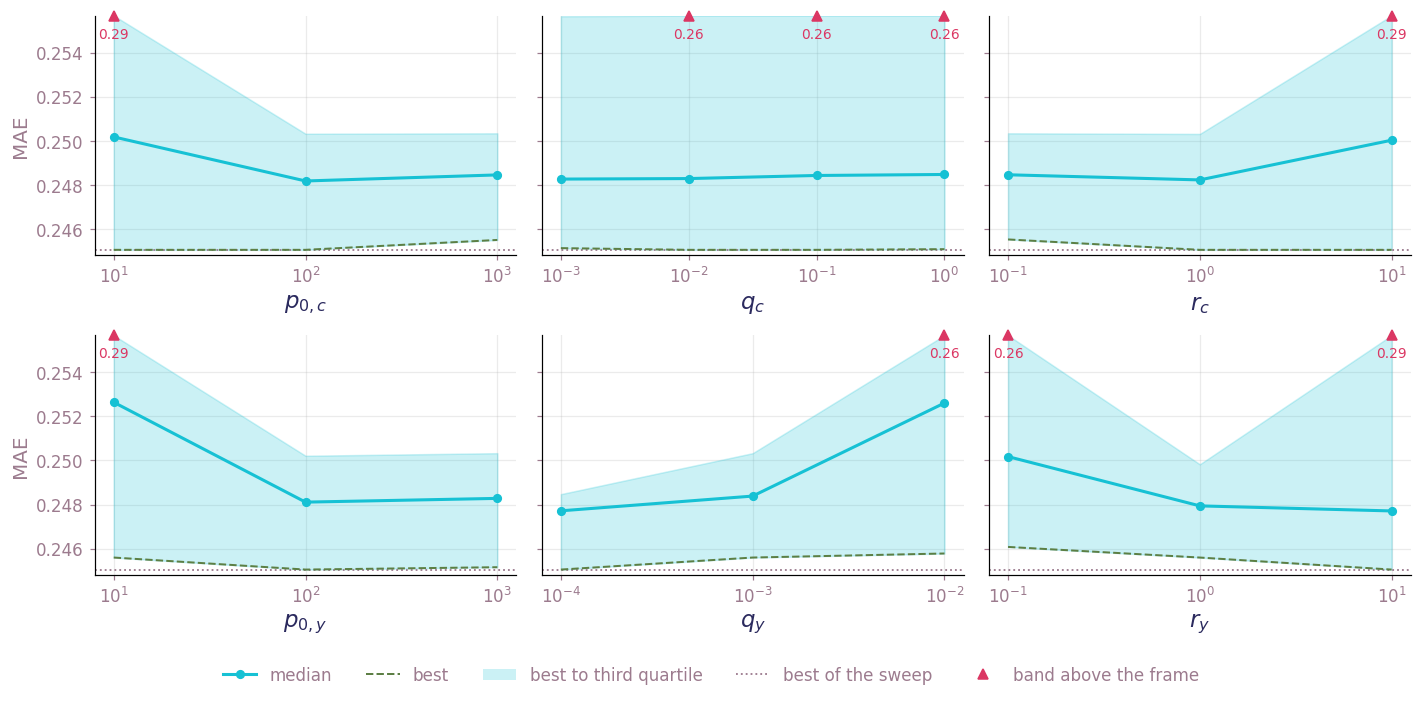

melhor MAE da varredura: 0.2451   pior: 0.6416
eixo vertical cortado em 0.2557

quanto o MAE mediano se move ao longo de cada eixo

  q_y   varia 0.0049   0.0001:0.2477  0.001:0.2484  0.01:0.2526
  p0_y  varia 0.0045   10:0.2526  100:0.2481  1000:0.2483
  r_y   varia 0.0025   0.1:0.2502  1:0.2479  10:0.2477
  p0_c  varia 0.0020   10:0.2502  100:0.2482  1000:0.2485
  r_c   varia 0.0018   0.1:0.2485  1:0.2482  10:0.2500
  q_c   varia 0.0002   0.001:0.2483  0.01:0.2483  0.1:0.2484  1:0.2485


In [151]:
# O que cada hiperparâmetro faz com o erro.
#
# Para cada valor da grade, a linha é o MAE mediano entre todas as combinações
# dos outros cinco, e a faixa vai do melhor ao terceiro quartil. O eixo vertical
# é cortado na faixa útil, e um triângulo no topo marca os valores cuja faixa sai
# do quadro, com o número escrito ao lado.

if "full" not in globals():
    full = pd.read_csv(ARQ_FULL)

EIXOS_FIG = ["p0_c", "q_c", "r_c", "p0_y", "q_y", "r_y"]
ROT_FIG = {"p0_c": "$p_{0,c}$", "q_c": "$q_c$", "r_c": "$r_c$",
           "p0_y": "$p_{0,y}$", "q_y": "$q_y$", "r_y": "$r_y$"}
TAM_ROT, TAM_MARCA = 13, 11

def rotulo_valor(v):
    e_ = np.log10(v)
    return (f"$10^{{{int(round(e_))}}}$" if abs(e_ - round(e_)) < 1e-9
            else f"{v:g}")

# estatísticas por eixo e por nível
stats = {e: {v: full.loc[np.isclose(full[e], v), "MAE"] for v in sorted(full[e].unique())}
         for e in EIXOS_FIG}
melhor_geral = float(full.MAE.min())
# o teto ignora as medianas extremas, para a variação da maioria ocupar a altura
# do quadro. O que passar disso é marcado com um triângulo e o valor ao lado.
medianas = np.array([s_.median() for d_ in stats.values() for s_ in d_.values()])
teto = float(np.quantile(medianas, 0.90)) * 1.02
piso = melhor_geral * 0.999

fig, ax = plt.subplots(2, 3, figsize=(13, 6.4), facecolor="white", sharey=True)
for a_, e in zip(ax.ravel(), EIXOS_FIG):
    niveis = list(stats[e])
    med = [stats[e][v].median() for v in niveis]
    baixo = [stats[e][v].min() for v in niveis]
    alto = [stats[e][v].quantile(0.75) for v in niveis]
    x = np.arange(len(niveis))
    a_.fill_between(x, baixo, np.minimum(alto, teto), color=C_KAL, alpha=.22, zorder=2)
    a_.plot(x, np.minimum(med, teto), "o-", lw=2, ms=5, color=C_KAL, zorder=4)
    a_.plot(x, baixo, ls="--", lw=1.3, color=C_TRES, zorder=3)
    a_.axhline(melhor_geral, color=C_EIXO, ls=":", lw=1.2)
    # o que sai do quadro vira triângulo no topo, com o valor ao lado
    for xi, a2_, m_ in zip(x, alto, med):
        fora = max(a2_ if a2_ > teto else 0, m_ if m_ > teto else 0)
        if fora:
            a_.plot(xi, teto, marker="^", ms=7, color=C_REW, clip_on=False, zorder=6)
            rot = f"{m_:.3f}" if m_ > teto else f"{a2_:.2f}"
            a_.text(xi, teto * 0.998, rot, ha="center", va="top",
                    fontsize=TAM_MARCA - 2, color=C_REW)
    a_.set_xticks(x); a_.set_xticklabels([rotulo_valor(v) for v in niveis])
    a_.set_xlabel(ROT_FIG[e], color=C_TIT, fontsize=TAM_ROT + 2)
    a_.tick_params(colors=C_EIXO, labelsize=TAM_MARCA)
ax[0, 0].set_ylim(piso, teto)
for a_ in ax[:, 0]:
    a_.set_ylabel("MAE", color=C_EIXO, fontsize=TAM_ROT)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
chaves = [Line2D([], [], marker="o", color=C_KAL, lw=2, ms=5, label="median"),
          Line2D([], [], ls="--", color=C_TRES, lw=1.3, label="best"),
          Patch(facecolor=C_KAL, alpha=.22, label="best to third quartile"),
          Line2D([], [], ls=":", color=C_EIXO, lw=1.2, label="best of the sweep"),
          Line2D([], [], marker="^", color=C_REW, ls="none", ms=7,
                 label="band above the frame")]
leg = fig.legend(handles=chaves, frameon=False, fontsize=TAM_MARCA,
                 loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.0),
                 labelcolor=C_EIXO)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

print(f"melhor MAE da varredura: {melhor_geral:.4f}   pior: {full.MAE.max():.4f}")
print(f"eixo vertical cortado em {teto:.4f}\n")
print("quanto o MAE mediano se move ao longo de cada eixo\n")
mov = {e: max(s.median() for s in stats[e].values()) - min(s.median() for s in stats[e].values())
       for e in EIXOS_FIG}
for e, v in sorted(mov.items(), key=lambda t: -t[1]):
    print(f"  {e:5s} varia {v:.4f}   " +
          "  ".join(f"{k:g}:{stats[e][k].median():.4f}" for k in stats[e]))

---
## 7. Other binarisation rules

The binarisation decides which examples fall on the same address, and with that
it decides how many visits each address receives. This section changes only the
rule that places the thresholds, keeping everything else fixed, and compares
three forms.

**Linear.** Thresholds evenly spaced between the minimum and the maximum of the
attribute in the training set. It is the `DynamicThermometer` of wisardpkg, the
one the thesis code runs, and it serves as the reference here.

**Distributive.** Thresholds at the percentiles of the attribute, so that each
band receives approximately the same number of training examples. The rule is the
one of Bacellar et al., ESANN 2022.

**Gaussian.** Thresholds at the quantiles of a normal fitted to the mean and the
deviation of the attribute. It concentrates resolution at the centre of the
distribution and spends little on the tails.

After the one-hot encoding of Section 0, a large share of the attributes is
binary, and for a binary attribute the distributive rule degenerates, because the
thresholds coincide and the bits are repeated. The cell counts how many
attributes fall in that case.


294 de 332 atributos são binários (89%), e neles o distributivo degenera

dynamic e linear produzem a mesma binarização: True

  dynamic    mediana de 6 visitas, 23% vistos uma vez, 23,171 endereços   (53s)
  linear     mediana de 6 visitas, 23% vistos uma vez, 23,171 endereços   (105s)
  distributivo mediana de 8 visitas, 21% vistos uma vez, 18,232 endereços   (160s)
  gaussiano  mediana de 15 visitas, 15% vistos uma vez, 13,052 endereços   (215s)

MELHOR DE CADA UM  (thermometer 27, tupla 6, 3 execuções)

     encoder    modelo            media    MAE  MAE_dp   RMSE     R2  visitas_mediana  pct_uma
     dynamic R-KalWeNN K-Harmonic power 0.2459  0.0002 0.3309 0.3367           6.0000  23.2834
      linear R-KalWeNN K-Harmonic power 0.2459  0.0002 0.3309 0.3367           6.0000  23.2834
distributivo R-KalWeNN       K-Harmonic 0.2511  0.0006 0.3364 0.3142           8.0000  21.2484
   gaussiano R-KalWeNN       K-Harmonic 0.2522  0.0003 0.3382 0.3068          15.0000  15.4536
     dynamic

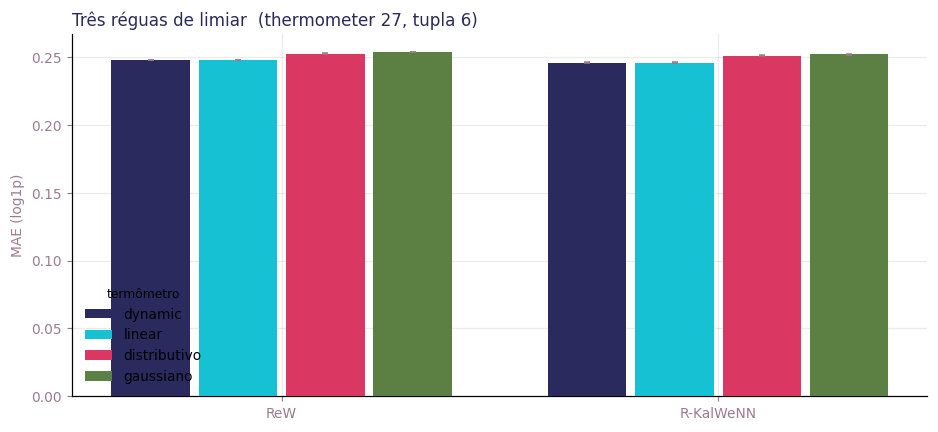

In [116]:
from scipy.stats import norm

def termometro_distributivo(X, t, Xref):
    """Termômetro distributivo: limiares nos percentis do atributo, medidos
    em Xref (o treino), de modo que cada faixa receba aproximadamente o mesmo
    número de exemplos."""
    X = np.atleast_2d(np.asarray(X, dtype=float))
    Xref = np.asarray(Xref, dtype=float)
    saida = np.empty((X.shape[0], X.shape[1] * t), dtype=np.uint8)
    for j in range(X.shape[1]):
        limiares = np.quantile(Xref[:, j], np.arange(t) / t)
        saida[:, j*t:(j+1)*t] = (X[:, [j]] > limiares).astype(np.uint8)
    return saida


def termometro_gaussiano(X, t, Xref):
    """Limiares nos quantis de uma normal com a média e o desvio do atributo."""
    X = np.atleast_2d(np.asarray(X, dtype=float))
    Xref = np.asarray(Xref, dtype=float)
    saida = np.empty((X.shape[0], X.shape[1] * t), dtype=np.uint8)
    for j in range(X.shape[1]):
        mu, sd = Xref[:, j].mean(), Xref[:, j].std()
        if sd == 0:
            sd = 1e-12
        limiares = mu + sd * norm.ppf(np.arange(1, t + 1) / (t + 1))
        saida[:, j*t:(j+1)*t] = (X[:, [j]] > limiares).astype(np.uint8)
    return saida


THERM_9, TUPLA_9 = THERM, TUPLA
SEEDS_9 = (0, 1, 2)

binarios = int(sum(len(np.unique(X_train[:, j])) <= 2 for j in range(N_ATRIB)))
print(f"{binarios} de {N_ATRIB} atributos são binários "
      f"({100*binarios/N_ATRIB:.0f}%), e neles o distributivo degenera\n")

ENCODERS = {
    "dynamic":      lambda X, t: termometro(X, t, mins, maxs),
    "linear":       lambda X, t: termometro(X, t, mins, maxs),
    "distributivo": lambda X, t: termometro_distributivo(X, t, X_train),
    "gaussiano":    lambda X, t: termometro_gaussiano(X, t, X_train),
}

# "dynamic" e "linear" chamam a MESMA função: o DynamicThermometer do wisardpkg
# tem limiares igualmente espaçados, então os dois nomes descrevem a mesma régua.
# As duas linhas da tabela existem só para mostrar isso lado a lado.
_a = ENCODERS["dynamic"](X_train, THERM_9)
_b = ENCODERS["linear"](X_train, THERM_9)
print(f"dynamic e linear produzem a mesma binarização: {np.array_equal(_a, _b)}\n")

linhas9, t0 = [], time.perf_counter()
for nome, enc in ENCODERS.items():
    Xb_t, Xb_s = enc(X_train, THERM_9), enc(X_test, THERM_9)
    acc, vis = {}, None
    for sd in SEEDS_9:
        mp = sorteia_mapping(Xb_t.shape[1], TUPLA_9, seed=sd)
        if vis is None:
            dg = diagnostico(Xb_t, y_train, mp)
            vis, uma = dg["mediana"], 100.0 * float((dg["visitas"] == 1).mean())
            ocup = len(dg["visitas"])
        pr = ReW(mp).fit(Xb_t, y_train).pares(Xb_s)
        for m, f in MEDIAS_REW.items():
            acc.setdefault(("ReW", m), []).append(metricas(y_test, [f(l) for l in pr]))
        pk = RKalWeNN(mp, seed=sd, **PADRAO).fit(Xb_t, y_train).pares(Xb_s)
        for m, f in MEDIAS_KAL.items():
            acc.setdefault(("R-KalWeNN", m), []).append(metricas(y_test, [f(l) for l in pk]))
    for (modelo, m), vals in acc.items():
        v = np.array([[a, b, c] for a, b, c, _, _ in vals])
        linhas9.append(dict(encoder=nome, modelo=modelo, media=m,
                            MAE=v[:, 0].mean(), MAE_dp=v[:, 0].std(ddof=1),
                            RMSE=v[:, 1].mean(), R2=v[:, 2].mean(),
                            visitas_mediana=vis, pct_uma=uma, enderecos=ocup))
    print(f"  {nome:<10} mediana de {vis:.0f} visitas, {uma:.0f}% vistos uma vez, "
          f"{ocup:,} endereços   ({time.perf_counter()-t0:.0f}s)")

enc9 = pd.DataFrame(linhas9)
enc9.to_csv("termometros_08.csv", index=False)

melhor = enc9.loc[enc9.groupby(["encoder", "modelo"]).MAE.idxmin()]
print(f"\nMELHOR DE CADA UM  (thermometer {THERM_9}, tupla {TUPLA_9}, "
      f"{len(SEEDS_9)} execuções)\n")
print(melhor[["encoder", "modelo", "media", "MAE", "MAE_dp", "RMSE", "R2",
              "visitas_mediana", "pct_uma"]]
      .sort_values(["modelo", "MAE"])
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

C_ENC = {"dynamic": "#2b2a5e", "linear": "#16c1d4",
         "distributivo": "#db3763", "gaussiano": "#5c7f44"}
fig, ax = plt.subplots(figsize=(8.6, 4), facecolor="white")
larg, modelos = 0.20, ["ReW", "R-KalWeNN"]
x = np.arange(len(modelos))
for i, (nome, cor) in enumerate(C_ENC.items()):
    g = melhor[melhor.encoder == nome].set_index("modelo").loc[modelos]
    ax.bar(x + (i - 1.5) * larg, g.MAE, larg * 0.9, yerr=g.MAE_dp, color=cor,
           label=nome, zorder=3, error_kw=dict(ecolor=C_EIXO, elinewidth=1, capsize=2))
ax.set_xticks(x); ax.set_xticklabels(modelos)
ax.set_ylabel("MAE (log1p)", color=C_EIXO)
ax.set_title(f"Três réguas de limiar  (thermometer {THERM_9}, tupla {TUPLA_9})",
             color=C_TIT, fontsize=11, loc="left")
ax.tick_params(colors=C_EIXO)
ax.legend(frameon=False, fontsize=9, title="termômetro", title_fontsize=8)
plt.tight_layout(); plt.show()